<a href="https://colab.research.google.com/github/paolamrk/Practica3_MachineLearning/blob/main/practica_clasificadores_integrante1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import make_classification, load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Dataset Sintético con ruido estructurado (Responsabilidad del Integrante 1)
X_sintetico, y_sintetico = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=4,
    n_redundant=2,
    n_classes=3,
    n_clusters_per_class=1,
    weights=[0.33, 0.33, 0.34],
    flip_y=0.05,
    class_sep=1.0,
    random_state=42
)

# Agregar ruido correlacionado a las primeras dos características
rng = np.random.default_rng(42)
ruido = rng.normal(0, 0.5, size=len(X_sintetico))
X_sintetico[:, 0] += ruido
X_sintetico[:, 1] += ruido

# 2. Dataset Wine (Benchmark Real)
wine = load_wine()
X_wine, y_wine = wine.data, wine.target

print(f"Dataset Sintético creado: {X_sintetico.shape[0]} muestras y {X_sintetico.shape[1]} características.")
print(f"Dataset Wine cargado: {X_wine.shape[0]} muestras y {X_wine.shape[1]} características.")

Dataset Sintético creado: 1000 muestras y 6 características.
Dataset Wine cargado: 178 muestras y 13 características.


In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin

class DistanciaMinima(BaseEstimator, ClassifierMixin):
    """Clasificador de Distancia Mínima a Centroides desde cero."""

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        # Calcular el centroide (promedio) de cada clase
        self.centroides_ = np.array([
            X[y == clase].mean(axis=0) for clase in self.classes_
        ])
        return self

    def predict(self, X):
        X = np.asarray(X)
        # Calcular distancia euclidiana de cada muestra a todos los centroides
        distancias = np.linalg.norm(X[:, np.newaxis, :] - self.centroides_[np.newaxis, :, :], axis=2)
        indices = np.argmin(distancias, axis=1)
        return self.classes_[indices]

# --- PRUEBA Y MEDICIÓN DE TIEMPOS (Dataset Sintético) ---
X_train, X_test, y_train, y_test = train_test_split(
    X_sintetico, y_sintetico, test_size=0.30, random_state=42, stratify=y_sintetico
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelo_dm = DistanciaMinima()

# Medir tiempo de entrenamiento
inicio_train = time.perf_counter()
modelo_dm.fit(X_train_scaled, y_train)
tiempo_train = time.perf_counter() - inicio_train

# Medir tiempo de predicción
inicio_pred = time.perf_counter()
preds_dm = modelo_dm.predict(X_test_scaled)
tiempo_pred = time.perf_counter() - inicio_pred

acc_dm = accuracy_score(y_test, preds_dm)

print("--- Distancia Mínima (Dataset Sintético) ---")
print(f"Accuracy (Hold-Out 70/30): {acc_dm:.4f}")
print(f"Tiempo de entrenamiento: {tiempo_train:.6f} segundos")
print(f"Tiempo de predicción:    {tiempo_pred:.6f} segundos")

--- Distancia Mínima (Dataset Sintético) ---
Accuracy (Hold-Out 70/30): 0.7233
Tiempo de entrenamiento: 0.002971 segundos
Tiempo de predicción:    0.000513 segundos


In [ ]:
# --- PRUEBA Y MEDICIÓN DE TIEMPOS DE MLP BASE (Dataset Sintético) ---
# Creamos el modelo con una configuración estándar
modelo_mlp = MLPClassifier(max_iter=1000, random_state=42)

# Medir tiempo de entrenamiento (utilizando los datos escalados del Paso 3)
inicio_train = time.perf_counter()
modelo_mlp.fit(X_train_scaled, y_train)
tiempo_train_mlp = time.perf_counter() - inicio_train

# Medir tiempo de predicción
inicio_pred = time.perf_counter()
preds_mlp = modelo_mlp.predict(X_test_scaled)
tiempo_pred_mlp = time.perf_counter() - inicio_pred

acc_mlp = accuracy_score(y_test, preds_mlp)

print("--- Perceptrón Multicapa (MLP Base - Dataset Sintético) ---")
print(f"Accuracy (Hold-Out 70/30): {acc_mlp:.4f}")
print(f"Tiempo de entrenamiento: {tiempo_train_mlp:.6f} segundos")
print(f"Tiempo de predicción:    {tiempo_pred_mlp:.6f} segundos")

--- Perceptrón Multicapa (MLP Base - Dataset Sintético) ---
Accuracy (Hold-Out 70/30): 0.8400
Tiempo de entrenamiento: 3.241896 segundos
Tiempo de predicción:    0.001615 segundos


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# --- 1. EVALUACIÓN HOLD-OUT 70/30 EN DATASET WINE ---
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.30, random_state=42, stratify=y_wine
)

scaler_w = StandardScaler()
X_train_w_scaled = scaler_w.fit_transform(X_train_w)
X_test_w_scaled = scaler_w.transform(X_test_w)

# Distancia Mínima en Wine
modelo_dm_w = DistanciaMinima()
modelo_dm_w.fit(X_train_w_scaled, y_train_w)
preds_dm_w = modelo_dm_w.predict(X_test_w_scaled)
acc_dm_w = accuracy_score(y_test_w, preds_dm_w)

# MLP Base en Wine
modelo_mlp_w = MLPClassifier(max_iter=1000, random_state=42)
modelo_mlp_w.fit(X_train_w_scaled, y_train_w)
preds_mlp_w = modelo_mlp_w.predict(X_test_w_scaled)
acc_mlp_w = accuracy_score(y_test_w, preds_mlp_w)

print("=== EVALUACIÓN HOLD-OUT (70/30) EN DATASET WINE ===")
print(f"Distancia Mínima (Wine) - Accuracy: {acc_dm_w:.4f}")
print(f"MLP Base (Wine)         - Accuracy: {acc_mlp_w:.4f}\n")


# --- 2. VALIDACIÓN CRUZADA K-FOLD (K=5) EN AMBOS DATASETS ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pipelines para evitar filtración de datos durante las iteraciones de K-Fold
pipe_dm = Pipeline([('scaler', StandardScaler()), ('modelo', DistanciaMinima())])
pipe_mlp = Pipeline([('scaler', StandardScaler()), ('modelo', MLPClassifier(max_iter=1000, random_state=42))])

# K-Fold en Dataset Sintético
scores_dm_sint = cross_val_score(pipe_dm, X_sintetico, y_sintetico, cv=cv, scoring='accuracy')
scores_mlp_sint = cross_val_score(pipe_mlp, X_sintetico, y_sintetico, cv=cv, scoring='accuracy')

# K-Fold en Dataset Wine
scores_dm_wine = cross_val_score(pipe_dm, X_wine, y_wine, cv=cv, scoring='accuracy')
scores_mlp_wine = cross_val_score(pipe_mlp, X_wine, y_wine, cv=cv, scoring='accuracy')

print("=== VALIDACIÓN CRUZADA K-FOLD (K=5) ===")
print(f"Distancia Mínima (Sintético): {scores_dm_sint.mean():.4f} (±{scores_dm_sint.std():.4f})")
print(f"MLP Base (Sintético):         {scores_mlp_sint.mean():.4f} (±{scores_mlp_sint.std():.4f})")
print(f"Distancia Mínima (Wine):      {scores_dm_wine.mean():.4f} (±{scores_dm_wine.std():.4f})")
print(f"MLP Base (Wine):             {scores_mlp_wine.mean():.4f} (±{scores_mlp_wine.std():.4f})")

=== EVALUACIÓN HOLD-OUT (70/30) EN DATASET WINE ===
Distancia Mínima (Wine) - Accuracy: 0.9815
MLP Base (Wine)         - Accuracy: 1.0000



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perce

=== VALIDACIÓN CRUZADA K-FOLD (K=5) ===
Distancia Mínima (Sintético): 0.7020 (±0.0308)
MLP Base (Sintético):         0.8740 (±0.0086)
Distancia Mínima (Wine):      0.9775 (±0.0213)
MLP Base (Wine):             0.9776 (±0.0112)


In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Ocultar advertencias de convergencia durante la búsqueda exhaustiva
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Definir la rejilla de hiperparámetros para MLP
parametros_mlp = {
    'modelo__hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
    'modelo__activation': ['relu', 'tanh'],
    'modelo__alpha': [0.0001, 0.001, 0.01],
    'modelo__learning_rate_init': [0.001, 0.01]
}

def optimizar_mlp(X, y, nombre_dataset):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42, stratify=y
    )

    pipeline_mlp = Pipeline([
        ('scaler', StandardScaler()),
        ('modelo', MLPClassifier(max_iter=1000, random_state=42))
    ])

    grid_mlp = GridSearchCV(
        pipeline_mlp,
        param_grid=parametros_mlp,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_mlp.fit(X_train, y_train)
    test_acc = grid_mlp.score(X_test, y_test)

    print(f"=== OPTIMIZACIÓN MLP ({nombre_dataset.upper()}) ===")
    print("Mejores parámetros encontrados:")
    for param, val in grid_mlp.best_params_.items():
        print(f"  - {param}: {val}")
    print(f"Accuracy Validación Cruzada (Train): {grid_mlp.best_score_:.4f}")
    print(f"Accuracy Test (Hold-Out 70/30):      {test_acc:.4f}\n")
    return grid_mlp.best_params_, grid_mlp.best_score_, test_acc

# Ejecutar optimización para ambos conjuntos de datos
best_params_sint, best_cv_sint, test_acc_sint = optimizar_mlp(X_sintetico, y_sintetico, "Sintético")
best_params_wine, best_cv_wine, test_acc_wine = optimizar_mlp(X_wine, y_wine, "Wine")

=== OPTIMIZACIÓN MLP (SINTÉTICO) ===
Mejores parámetros encontrados:
  - modelo__activation: tanh
  - modelo__alpha: 0.0001
  - modelo__hidden_layer_sizes: (100,)
  - modelo__learning_rate_init: 0.001
Accuracy Validación Cruzada (Train): 0.8771
Accuracy Test (Hold-Out 70/30):      0.8400

=== OPTIMIZACIÓN MLP (WINE) ===
Mejores parámetros encontrados:
  - modelo__activation: relu
  - modelo__alpha: 0.0001
  - modelo__hidden_layer_sizes: (50, 50)
  - modelo__learning_rate_init: 0.01
Accuracy Validación Cruzada (Train): 0.9920
Accuracy Test (Hold-Out 70/30):      0.9815



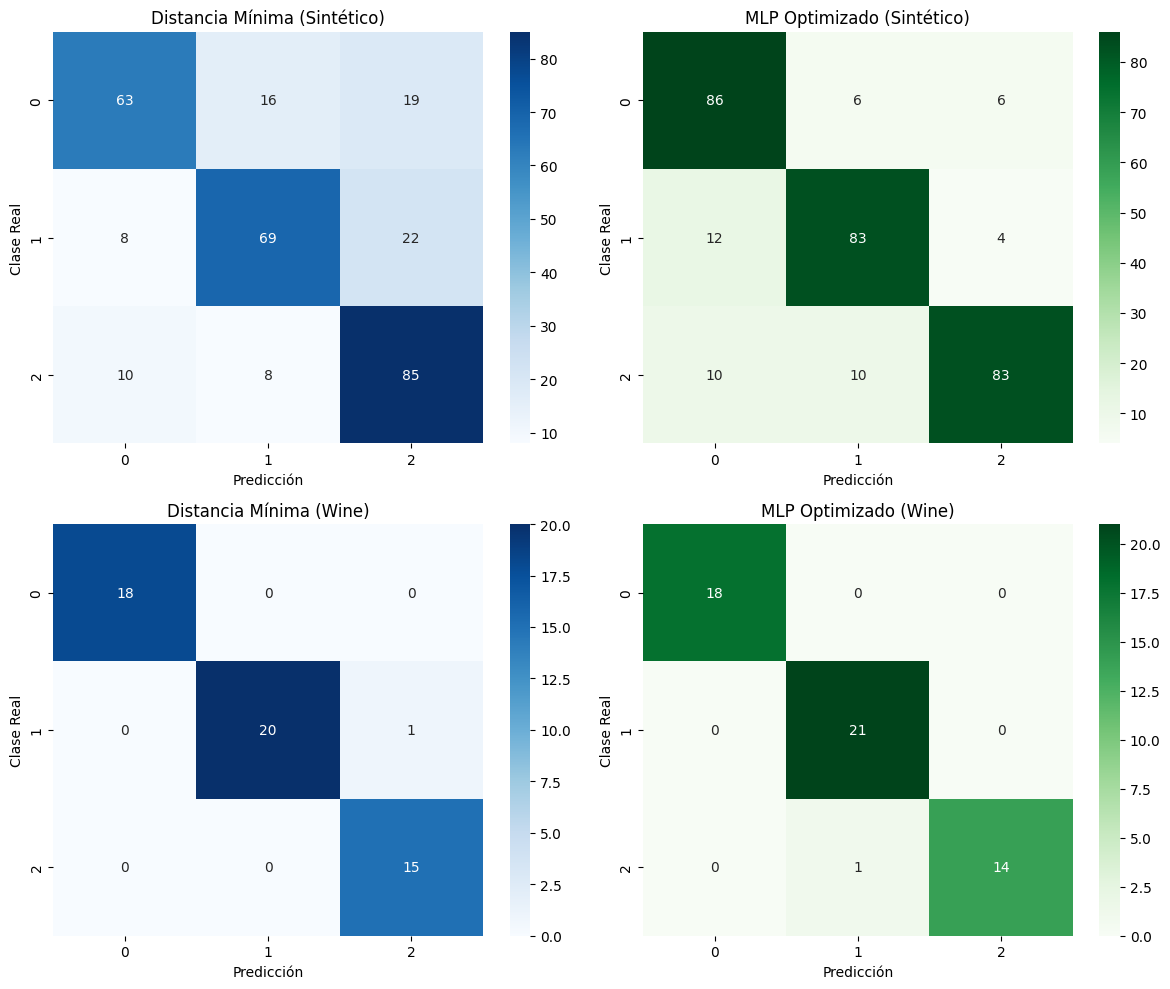

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Distancia Mínima - Sintético
sns.heatmap(confusion_matrix(y_test, preds_dm), annot=True, fmt='d', cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title('Distancia Mínima (Sintético)')
axes[0, 0].set_xlabel('Predicción')
axes[0, 0].set_ylabel('Clase Real')

# 2. MLP Optimizado - Sintético
mlp_opt_sint = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', MLPClassifier(hidden_layer_sizes=(100,), activation='tanh', alpha=0.0001, learning_rate_init=0.001, max_iter=1000, random_state=42))
])
mlp_opt_sint.fit(X_train, y_train)
preds_mlp_opt_sint = mlp_opt_sint.predict(X_test)

sns.heatmap(confusion_matrix(y_test, preds_mlp_opt_sint), annot=True, fmt='d', cmap='Greens', ax=axes[0, 1])
axes[0, 1].set_title('MLP Optimizado (Sintético)')
axes[0, 1].set_xlabel('Predicción')
axes[0, 1].set_ylabel('Clase Real')

# 3. Distancia Mínima - Wine
sns.heatmap(confusion_matrix(y_test_w, preds_dm_w), annot=True, fmt='d', cmap='Blues', ax=axes[1, 0])
axes[1, 0].set_title('Distancia Mínima (Wine)')
axes[1, 0].set_xlabel('Predicción')
axes[1, 0].set_ylabel('Clase Real')

# 4. MLP Optimizado - Wine
mlp_opt_wine = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', MLPClassifier(hidden_layer_sizes=(50, 50), activation='relu', alpha=0.0001, learning_rate_init=0.01, max_iter=1000, random_state=42))
])
mlp_opt_wine.fit(X_train_w, y_train_w)
preds_mlp_opt_wine = mlp_opt_wine.predict(X_test_w)

sns.heatmap(confusion_matrix(y_test_w, preds_mlp_opt_wine), annot=True, fmt='d', cmap='Greens', ax=axes[1, 1])
axes[1, 1].set_title('MLP Optimizado (Wine)')
axes[1, 1].set_xlabel('Predicción')
axes[1, 1].set_ylabel('Clase Real')

plt.tight_layout()
plt.show()